<a href="https://colab.research.google.com/github/ReneMarkovic/modelska_fizika_vaje/blob/main/Gradient_descent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Gradientni spust kot fizikalni optimizacijski koncept

V fiziki se sistemi naravno nagibajo k iskanju stanja z **najnižjo možno energijo** (princip minimalne potencialne energije).

Če si predstavljamo hribovito pokrajino, kjer višina predstavlja potencialno energijo $U(x, y)$, se bo kroglica, postavljena na hrib, zakotalila navzdol v smeri najstrmejšega spusta. Sila, ki deluje na kroglico, je povezana z gradientom potencialne energije:

$$\vec{F} = -\nabla U$$

Ker se kroglica giblje v smeri sile, se giblje v nasprotni smeri gradienta ($-\nabla U$). To je natanko fizikalni ekvivalent **gradientnega spusta**, kjer z majhnimi koraki (ki jih določa hitrost učenja ali v fiziki dinamika telesa) iščemo lokalni ali globalni minimum energije.

## 1. Primer: Preprosta parabolična dolina (1D harmonični oscilator)

**Opis problema:** Kroglica se nahaja v idealni parabolični posodi, kjer je potencialna energija podana kot $U(x) = \frac{1}{2} k x^2$. Želimo najti ravnovesno lego (minimum energije), ki je pri $x = 0$.

**Uporaba koncepta:** Gradient potenciala je $\frac{dU}{dx} = kx$. Pravilo posodabljanja lege (gradientni spust) je:
$$x_{nov} = x_{stari} - \alpha \frac{dU}{dx}$$

kjer je $\alpha$ parameter koraka učenja (v fiziki povezan z viskoznostjo oz. dušenjem).

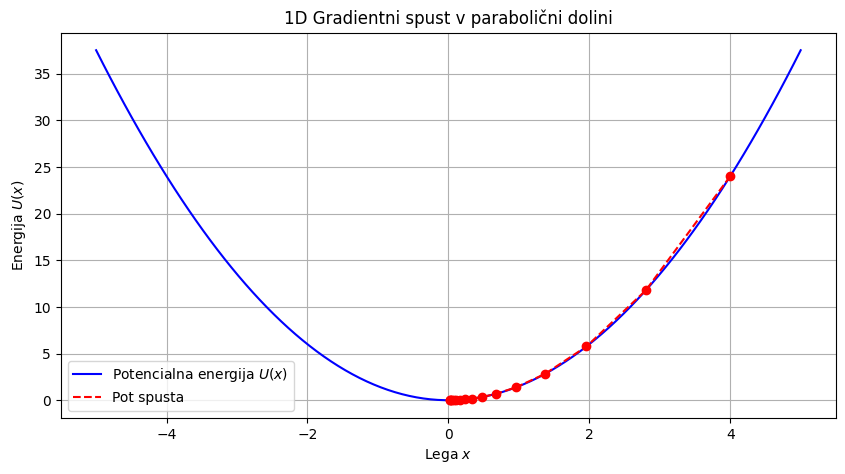

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Definicija potenciala in gradienta
def U(x):
    return 0.5 * 3 * x**2

def gradient_U(x):
    return 3 * x

# Parametri gradientnega spusta
alpha = 0.1
x = 4.0 # začetna lega
coordinates = [x]

for _ in range(15):
    grad = gradient_U(x)
    x = x - alpha * grad
    coordinates.append(x)

# Vizualizacija
xs = np.linspace(-5, 5, 100)
plt.figure(figsize=(10, 5))
plt.plot(xs, U(xs), label='Potencialna energija $U(x)$', color='blue')
coordinates = np.array(coordinates)
plt.scatter(coordinates, U(coordinates), color='red', zorder=5)
plt.plot(coordinates, U(coordinates), color='red', linestyle='--', label='Pot spusta')
plt.title('1D Gradientni spust v parabolični dolini')
plt.xlabel('Lega $x$')
plt.ylabel('Energija $U(x)$')
plt.legend()
plt.grid(True)
plt.show()

## 2. Primer: Gibanje v kompleksnejšem reliefu (Lokalni vs. Globalni minimum)

**Opis problema:** Realni fizikalni sistemi imajo pogosto več dolin (lokalnih minimumov). Predstavljajmo si potencialno funkcijo z več minimumi, npr. $U(x) = x^4 - 5x^2 - 3x$.

**Uporaba koncepta:** Če kroglico spustimo na napačni strani hriba, se bo ustavila v lokalnem minimumu in ne bo dosegla globalno najnižje točke.

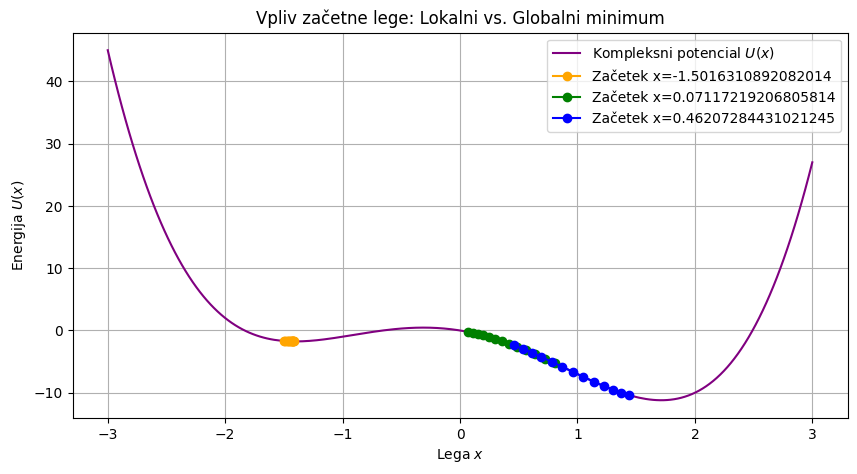

In [27]:
def U_complex(x):
    return x**4 - 5*x**2 - 3*x

def grad_complex(x):
    return 4*x**3 - 10*x - 3

lr = 0.01

# Dve različni začetni točki
tocke = [5*np.random.random()-2.5 for _ in range(3)]
plt.figure(figsize=(10, 5))
xs = np.linspace(-3, 3, 200)
plt.plot(xs, U_complex(xs), label='Kompleksni potencial $U(x)$', color='purple')

colors = ['orange', 'green','blue']
for start_x, col in zip(tocke, colors):
    x = start_x
    path = [x]
    for _ in range(12):
        x = x - lr * grad_complex(x)
        path.append(x)
    path = np.array(path)
    plt.plot(path, U_complex(path), color=col, marker='o', label=f'Začetek x={start_x}')

plt.title('Vpliv začetne lege: Lokalni vs. Globalni minimum')
plt.xlabel('Lega $x$')
plt.ylabel('Energija $U(x)$')
plt.legend()
plt.grid(True)
plt.show()

## 3. Primer: 2D Fizikalni sistem s sedlasto točko (Saddle Point)

**Opis problema:** V realnem svetu se energijske površine raztezajo v več dimenzijah. Predstavljajmo si gorsko sedlo (prelaz). Matematika in fizika tak prostor opisujeta s potencialom $U(x, y) = x^2 - y^2$ ali bolj zapletenimi oblikami, kot je npr. $U(x, y) = x^2 + 2y^2 - 0.5x y$.

Želimo najti najnižjo točko (stabilno ravnovesje). V dveh dimenzijah moramo hkrati posodabljati koordinati $x$ in $y$ v smeri negativnega gradienta:

$$\vec{x}_{nov} = \vec{x}_{stari} - \alpha \nabla U(x, y)$$

kjer je gradient definiran kot vektor delnih odvodov:

$$\nabla U(x, y) = \begin{pmatrix} \frac{\partial U}{\partial x} \\ \frac{\partial U}{\partial y} \end{pmatrix}$$

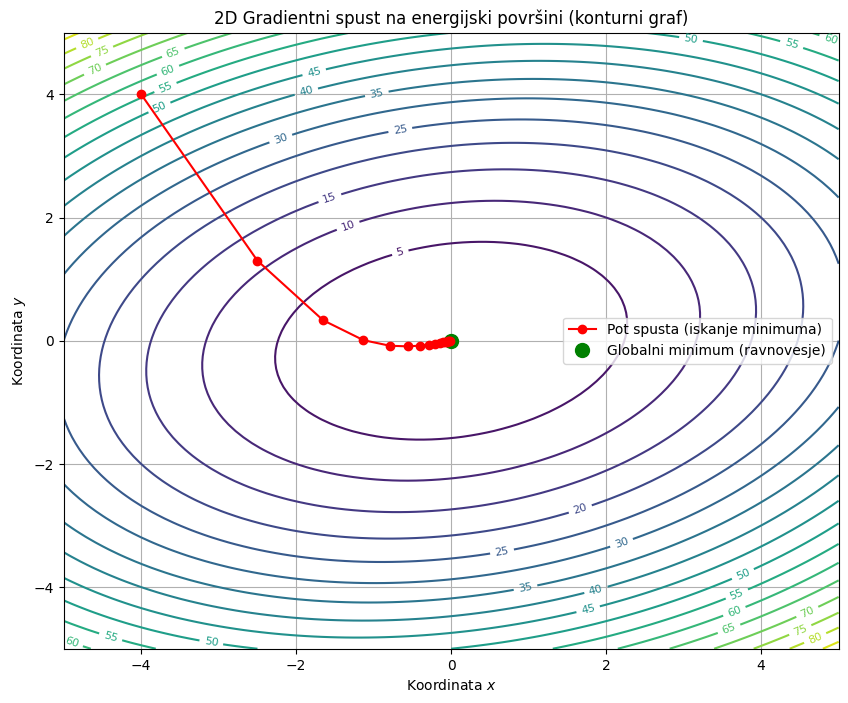

In [15]:
# Definicija 2D potenciala in njegovega gradienta
def U_2d(x, y):
    return x**2 + 2*y**2 - 0.5*x*y

def grad_2d(x, y):
    df_dx = 2*x - 0.5*y
    df_dy = 4*y - 0.5*x
    return np.array([df_dx, df_dy])

# Izvedba gradientnega spusta
alpha_2d = 0.15
tocka_2d = np.array([-4.0, 4.0]) # Začetna točka visoko v hribih
pot_2d = [tocka_2d]

for _ in range(15):
    g = grad_2d(tocka_2d[0], tocka_2d[1])
    tocka_2d = tocka_2d - alpha_2d * g
    pot_2d.append(tocka_2d)

pot_2d = np.array(pot_2d)

# Ustvarjanje mreže za konturni graf
x_vals = np.linspace(-5, 5, 100)
y_vals = np.linspace(-5, 5, 100)
X, Y = np.meshgrid(x_vals, y_vals)
Z = U_2d(X, Y)

# Izris 2D poti spusta na konturnem grafu
plt.figure(figsize=(10, 8))
contours = plt.contour(X, Y, Z, levels=20, cmap='viridis')
plt.clabel(contours, inline=True, fontsize=8)
plt.plot(pot_2d[:, 0], pot_2d[:, 1], 'r-o', label='Pot spusta (iskanje minimuma)', zorder=5)
plt.plot(0, 0, 'go', markersize=10, label='Globalni minimum (ravnovesje)')
plt.title('2D Gradientni spust na energijski površini (konturni graf)')
plt.xlabel('Koordinata $x$')
plt.ylabel('Koordinata $y$')
plt.legend()
plt.grid(True)
plt.show()

## 4. Primer: Gradientni spust z momentom (Fizikalna vztrajnost)

**Opis problema:** V prejšnjem primeru z več minimumi se je kroglica ujela v lokalni minimum, ker nima vztrajnosti. V fiziki ima kroglica maso in s tem gibalno količino (moment). Ko se kotali navzdol, nabira hitrost, kar ji omogoča, da premaga manjše ovire.

**Uporaba koncepta:** Klasični formuli dodamo člen za moment (vztrajnost) $\beta$:

$$v_{nov} = \beta v_{stari} + (1 - \beta) \nabla U(x)$$
$$x_{nov} = x_{stari} - \alpha v_{nov}$$

kjer $v$ predstavlja hitrost (moment) kroglice.

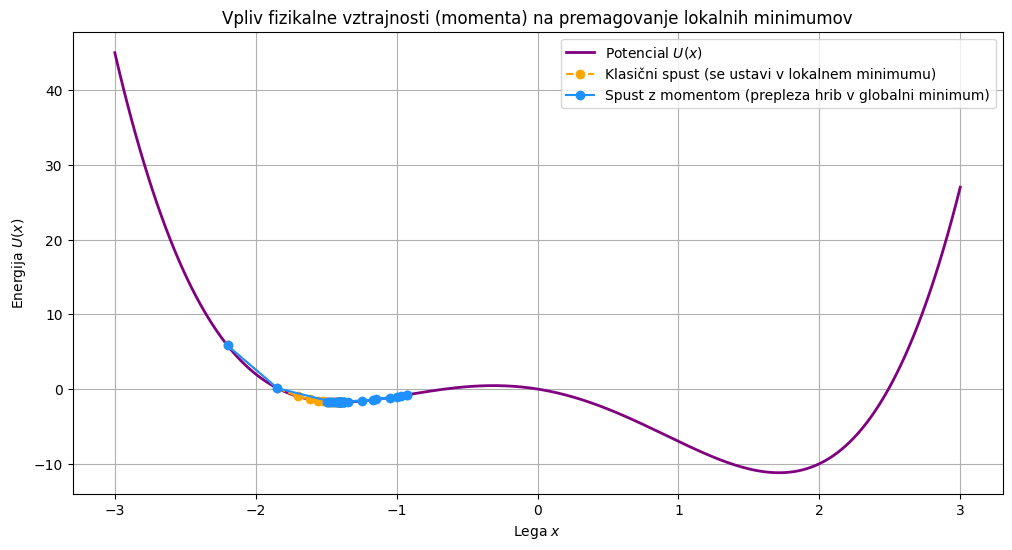

In [16]:
# Ponovno uporabimo kompleksni potencial iz 2. primera z varnimi fizikalnimi parametri
def U_complex(x):
    return x**4 - 5*x**2 - 3*x

def grad_complex(x):
    return 4*x**3 - 10*x - 3

# Popravljeni, stabilni parametri za simulacijo
alpha = 0.015       # Manjši korak preprečuje numerično nestabilnost
beta = 0.7         # Koeficient vztrajnosti (momentum)

# 1. Simulacija brez momenta (navaden gradientni spust)
x_simple = -2.2
path_simple = [x_simple]
for _ in range(40):
    x_simple = x_simple - alpha * grad_complex(x_simple)
    path_simple.append(x_simple)

# 2. Simulacija z momentom (fizikalna vztrajnost)
x_momentum = -2.2
v = 0.0
path_momentum = [x_momentum]
for _ in range(40):
    # Hitrost je kombinacija prejšnje hitrosti in sile (negativnega gradienta)
    v = beta * v - alpha * grad_complex(x_momentum)
    x_momentum = x_momentum + v
    path_momentum.append(x_momentum)

# Grafični prikaz
plt.figure(figsize=(12, 6))
xs = np.linspace(-3, 3, 200)
plt.plot(xs, U_complex(xs), label='Potencial $U(x)$', color='purple', lw=2)
plt.plot(path_simple, U_complex(np.array(path_simple)), 'o--', color='orange', label='Klasični spust (se ustavi v lokalnem minimumu)')
plt.plot(path_momentum, U_complex(np.array(path_momentum)), 'o-', color='dodgerblue', label='Spust z momentom (prepleza hrib v globalni minimum)')
plt.title('Vpliv fizikalne vztrajnosti (momenta) na premagovanje lokalnih minimumov')
plt.xlabel('Lega $x$')
plt.ylabel('Energija $U(x)$')
plt.legend()
plt.grid(True)
plt.show()

## 5. Primer: Iskanje oblike viseče verižice z minimizacijo energije

**Fizikalni model:** Imamo $N$ točk (delcev z maso $m$), ki so med seboj zaporedno povezani z elastičnimi vzmetmi s togostjo $k$ in ravnovesno dolžino $L_0$. Prva in zadnja točka sta fiksno pritrjeni v steni.

Celotna potencialna energija sistema je:
$$U = \sum_{i=1}^{N} m g y_i + \sum_{i=1}^{N-1} \frac{1}{2} k (d_i - L_0)^2$$
kjer je $d_i = \sqrt{(x_{i+1} - x_i)^2 + (y_{i+1} - y_i)^2}$ razdalja med sosednjima točkama.

Z gradientnim spustom bomo hkrati premikali $y$-koordinate vseh prostih členov verižice navzdol po gradientu energije $\frac{\partial U}{\partial y_i}$, da najdemo stabilno ravnovesno obliko.

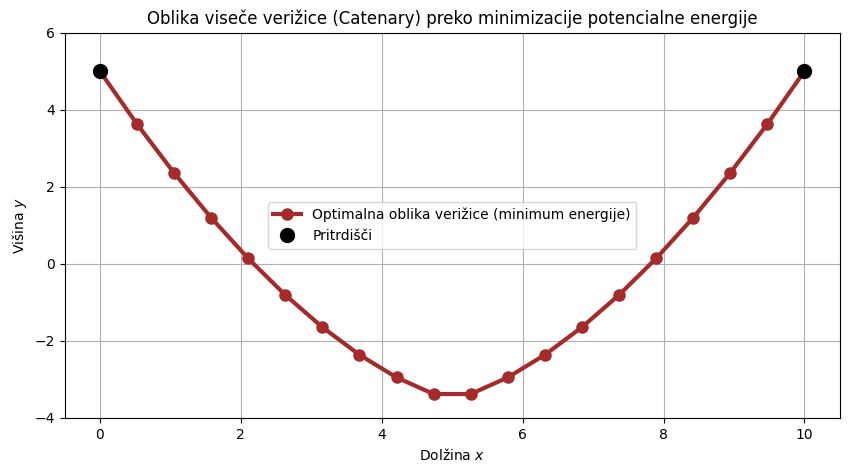

In [17]:
# Nastavitve verižice
N = 20                   # Število členov verižice
x_chain = np.linspace(0, 10, N)
y_chain = np.zeros(N)    # Začetna oblika: povsem ravna vrv med pritrdiščema

# Robni pogoji (prva in zadnja točka sta fiksni)
y_chain[0] = 5.0
y_chain[-1] = 5.0

# Fizikalne konstante
m = 0.5                  # Masa posameznega člena
g = 9.81                 # Gravitacijski pospešek
k_spring = 50.0          # Togost vrvice
L0 = 10.0 / (N - 1)      # Ravnovesna dolžina dela vrvice

# Gradientni spust za iskanje minimuma energije
alpha_chain = 0.005
iterations = 800

# Simulacija spusta skozi čas (iskanje ravnovesja)
for _ in range(iterations):
    # Izračun sil (negativnih gradientov) na vsak notranji člen
    grad_y = np.zeros(N)
    for i in range(1, N - 1):
        # Gravitacijski prispevek gradientu
        g_force = m * g

        # Prispevek leve vzmeti
        dx_left = x_chain[i] - x_chain[i-1]
        dy_left = y_chain[i] - y_chain[i-1]
        dist_left = np.sqrt(dx_left**2 + dy_left**2)
        spring_force_left = k_spring * (dist_left - L0) * (dy_left / dist_left)

        # Prispevek desne vzmeti
        dx_right = x_chain[i+1] - x_chain[i]
        dy_right = y_chain[i+1] - y_chain[i]
        dist_right = np.sqrt(dx_right**2 + dy_right**2)
        spring_force_right = k_spring * (dist_right - L0) * (-dy_right / dist_right)

        # Gradient je negirana sila
        grad_y[i] = g_force + spring_force_left + spring_force_right

    # Posodobitev pozicij (notranjih členov)
    y_chain[1:-1] = y_chain[1:-1] - alpha_chain * grad_y[1:-1]

# Vizualizacija stabilne verižice s popravljenim razponom osi
plt.figure(figsize=(10, 5))
plt.plot(x_chain, y_chain, 'o-', color='brown', lw=3, markersize=8, label='Optimalna oblika verižice (minimum energije)')
plt.plot([x_chain[0], x_chain[-1]], [y_chain[0], y_chain[-1]], 'ko', markersize=10, label='Pritrdišči')
plt.title('Oblika viseče verižice (Catenary) preko minimizacije potencialne energije')
plt.xlabel('Dolžina $x$')
plt.ylabel('Višina $y$')
plt.legend()
plt.grid(True)
plt.ylim(-4, 6) # Popravljen razpon, da se vidi celotna krivulja
plt.show()

## 6. Primer: Viseča verižica iz popolnoma naključne začetne lege

**Opis nadgradnje:** Da preizkusimo robustnost optimizacijskega algoritma, bomo notranje člene verižice na začetku postavili na povsem naključne višine ($y$).

Z vizualizacijo bomo prikazali začetno naključno stanje, vmesno stanje po nekaj iteracijah in končno stabilno fizikalno stanje po končanem gradientnem spustu.

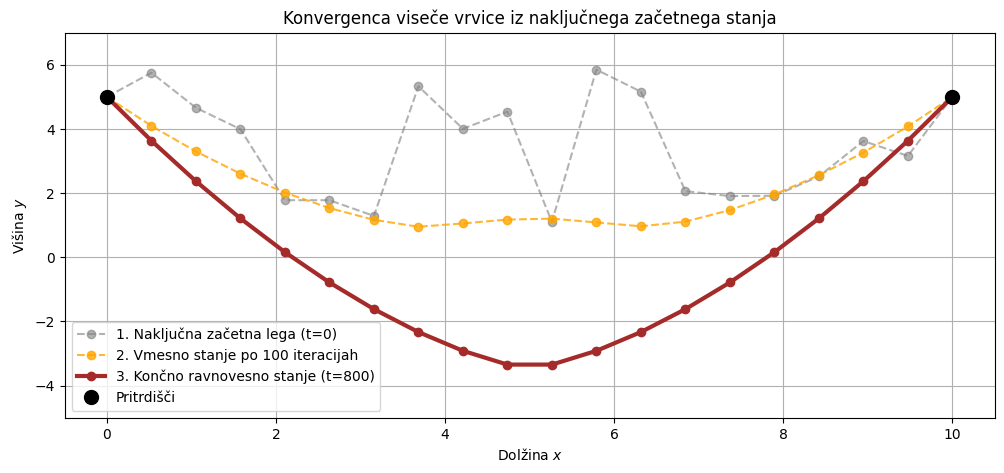

In [18]:
# Nastavitve za simulacijo z naključno začetno lego
np.random.seed(42)  # Zagotavlja ponovljivost naključnih števil
N_rand = 20
x_rand = np.linspace(0, 10, N_rand)

# Začetek z naključnimi višinami med 1 in 6
y_rand = np.random.uniform(1.0, 6.0, N_rand)

# Robni pogoji (pritrdišči ostaneta fiksni na višini 5.0)
y_rand[0] = 5.0
y_rand[-1] = 5.0

# Shranimo si začetno stanje za kasnejši prikaz
y_start = y_rand.copy()

# Fizikalni parametri
m_r = 0.5
g_r = 9.81
k_r = 50.0
L0_r = 10.0 / (N_rand - 1)

# Parametri optimizacije
alpha_r = 0.005

# Shranili si bomo tudi vmesno stanje po 100 iteracijah
y_mid = None

for step in range(801):
    grad_y = np.zeros(N_rand)
    for i in range(1, N_rand - 1):
        g_force = m_r * g_r

        # Leva vzmet
        dx_l = x_rand[i] - x_rand[i-1]
        dy_l = y_rand[i] - y_rand[i-1]
        dist_l = np.sqrt(dx_l**2 + dy_l**2)
        s_force_l = k_r * (dist_l - L0_r) * (dy_l / dist_l)

        # Desna vzmet
        dx_r = x_rand[i+1] - x_rand[i]
        dy_r = y_rand[i+1] - y_rand[i]
        dist_r = np.sqrt(dx_r**2 + dy_r**2)
        s_force_r = k_r * (dist_r - L0_r) * (-dy_r / dist_r)

        grad_y[i] = g_force + s_force_l + s_force_r

    # Posodobitev pozicij
    y_rand[1:-1] = y_rand[1:-1] - alpha_r * grad_y[1:-1]

    if step == 100:
        y_mid = y_rand.copy()

# Vizualizacija treh faz konvergence
plt.figure(figsize=(12, 5))
plt.plot(x_rand, y_start, 'o--', color='gray', alpha=0.6, label='1. Naključna začetna lega (t=0)')
plt.plot(x_rand, y_mid, 'o--', color='orange', alpha=0.8, label='2. Vmesno stanje po 100 iteracijah')
plt.plot(x_rand, y_rand, 'o-', color='brown', lw=3, label='3. Končno ravnovesno stanje (t=800)')
plt.plot([x_rand[0], x_rand[-1]], [y_start[0], y_start[-1]], 'ko', markersize=10, label='Pritrdišči')

plt.title('Konvergenca viseče vrvice iz naključnega začetnega stanja')
plt.xlabel('Dolžina $x$')
plt.ylabel('Višina $y$')
plt.ylim(-5, 7)
plt.legend()
plt.grid(True)
plt.show()

## 7. Primer: Iskanje ravnovesne lege naboja v elektrostatiki (Coulombov zakon)

**Fizikalni model:**
Predstavljajmo si tri točkaste naboje vzdolž premice (1D):
1. Prvi naboj $q_1$ je fiksno pritrjen na koordinati $x_1 = -5$.
2. Drugi naboj $q_2$ je fiksno pritrjen na koordinati $x_2 = 5$.
3. Tretji naboj $q_3$ je prosto gibljiv med njima, njegova začetna lega pa je nekje zunaj središča (npr. $x_3 = -3$).

Celotna elektrostatična potencialna energija sistema (zanemarimo fiksni del med $q_1$ in $q_2$) je:
$$U(x_3) = \frac{k_e q_1 q_3}{|x_3 - x_1|} + \frac{k_e q_2 q_3}{|x_2 - x_3|}$$

kjer je $k_e$ Coulombova konstanta. Sila na prosti naboj je enaka negativnemu gradientu te energije:
$$F_3 = -\frac{dU}{dx_3}$$

Z gradientnim spustom bomo simulirali, kako se prosti naboj premika proti točki z minimalno potencialno energijo (kjer se odbojne sile uravnovesijo).

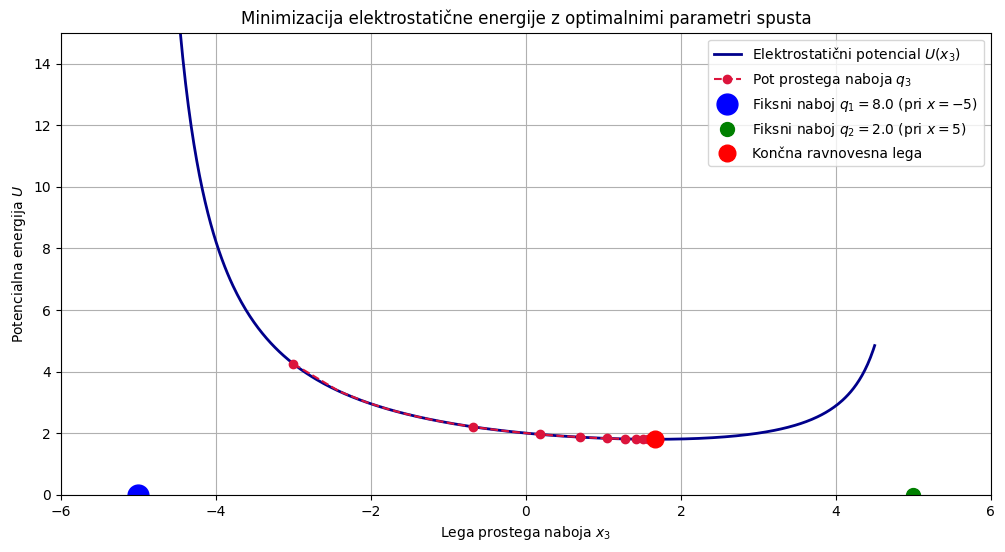

Končna lega s simulacijo: 1.6667
Teoretična ravnovesna lega: 1.6667


In [37]:
import numpy as np
import matplotlib.pyplot as plt

# Fizikalne konstante (poenostavljene)
ke = 1.0  # Coulombova konstanta
q1 = 8.0  # Velik naboj na levi
q2 = 2.0  # Manjši naboj na desni
q3 = 1.0  # Prosti testni naboj

x1 = -5.0
x2 = 5.0

# Definicija potencialne energije
def U_electrostatic(x3):
    # Preprečimo deljenje z nič blizu nabojev
    r1 = np.abs(x3 - x1)
    r2 = np.abs(x2 - x3)
    return ke * q3 * (q1 / r1 + q2 / r2)

# Odvod potencialne energije (gradient)
def grad_U_electrostatic(x3):
    r1 = x3 - x1
    r2 = x2 - x3

    # Pravilen analitični odvod potenciala:
    # d/dx3 (1/|x3-x1|) = -1/(x3-x1)^2  (za x3 > x1)
    # d/dx3 (1/|x2-x3|) = 1/(x2-x3)^2   (za x3 < x2)
    term1 = -ke * q1 * q3 / (r1**2)
    term2 = ke * q2 * q3 / (r2**2)

    # Gradient je seštevek obeh prispevkov sil
    return term1 + term2

# Parameter gradientnega spusta - optimalen korak in dovolj iteracij za popolno konvergenco

alpha_el = 0.3

x3 = -3.0  # Začetna lega prostega naboja
path_x3 = [x3]

# Optimizacija (več iteracij za popolno in natančno konvergenco v široki dolini)
for step in range(2500):
    g = grad_U_electrostatic(x3)
    x3_new = x3 - alpha_el * g
    # Varnostna omejitev (clipping) v varnem območju med nabojema
    x3 = np.clip(x3_new, -4.5, 4.5)
    path_x3.append(x3)

path_x3 = np.array(path_x3)

# Vizualizacija
xs = np.linspace(-4.5, 4.5, 500)
plt.figure(figsize=(12, 6))
plt.plot(xs, U_electrostatic(xs), label='Elektrostatični potencial $U(x_3)$', color='darkblue', lw=2)
plt.plot(path_x3, U_electrostatic(path_x3), 'o--', color='crimson', label='Pot prostega naboja $q_3$', markevery=10)

# Označitev nabojev
plt.plot(x1, 0, 'bo', markersize=15, label=f'Fiksni naboj $q_1 = {q1}$ (pri $x=-5$)')
plt.plot(x2, 0, 'go', markersize=10, label=f'Fiksni naboj $q_2 = {q2}$ (pri $x=5$)')
plt.plot(path_x3[-1], U_electrostatic(path_x3[-1]), 'ro', markersize=12, label='Končna ravnovesna lega')

plt.title('Minimizacija elektrostatične energije z optimalnimi parametri spusta')
plt.xlabel('Lega prostega naboja $x_3$')
plt.ylabel('Potencialna energija $U$')
plt.ylim(0, 15)  # Omejimo navpično os za boljšo preglednost
plt.xlim(-6, 6)
plt.legend()
plt.grid(True)
plt.show()

# Izračun teoretičnega ravnovesja za preverjanje:
ratio = np.sqrt(q1 / q2)
x_theoretical = (ratio * x2 + x1) / (ratio + 1)
print(f"Končna lega s simulacijo: {path_x3[-1]:.4f}")
print(f"Teoretična ravnovesna lega: {x_theoretical:.4f}")